In [1]:
# ------------------------------------------------------------
# 1. Imports
# ------------------------------------------------------------

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 2. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


Device: cuda


In [2]:
# ------------------------------------------------------------
# Load MNIST-1D from local pickle file
# ------------------------------------------------------------

import pickle

DATA_PATH = "./data/mnist1d_data.pkl"

with open(DATA_PATH, "rb") as f:
    data = pickle.load(f)

print(type(data))
print(data.keys())


<class 'dict'>
dict_keys(['x', 'x_test', 'y', 'y_test', 't', 'templates'])


In [ ]:
x_train = torch.tensor(data["x"]).to(torch.float32)
x_test = torch.tensor(data["x_test"]).to(torch.float32)

y_train = torch.tensor(data["y"])
y_test = torch.tensor(data["y_test"])

print("Train data shape:", x_train.shape)
print("Test data shape:", x_test.shape)


Train data shape: torch.Size([4000, 40])
Test data shape: torch.Size([1000, 40])


In [ ]:
train_dataset = TensorDataset(x_train, y_train)
test_dataset = TensorDataset(x_test, y_test)

print("\nDataset split:")
print("Train:", len(train_dataset))
print("Test :", len(test_dataset))


Dataset split:
Train: 4000
Test : 1000


In [ ]:
# ------------------------------------------------------------
# 7. DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 100

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)


In [ ]:
# ============================================================
# 8. Fully Connected Network
# ============================================================

class FCNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            # Hidden layer 1
            nn.Linear(40, 285),
            nn.ReLU(),
            # Hidden layer 2
            nn.Linear(285, 135),
            nn.ReLU(),
            # Hidden layer 3
            nn.Linear(135, 60),
            nn.ReLU(),
            # Output layer
            nn.Linear(60, 10)
        )

    def forward(self, x):
        return self.network(x)

# ============================================================
# 9. 1D Convolutional Network
# ============================================================

class CNN1D(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv1d(
            in_channels=1,
            out_channels=15,
            kernel_size=3,
            stride=2,
            padding=0
        )

        self.conv2 = nn.Conv1d(
            in_channels=15,
            out_channels=15,
            kernel_size=3,
            stride=2,
            padding=0
        )

        self.conv3 = nn.Conv1d(
            in_channels=15,
            out_channels=15,
            kernel_size=3,
            stride=2,
            padding=0
        )

        self.fc = nn.Linear(60, 10)

    def forward(self, x):
        x = x.unsqueeze(1)
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = torch.relu(self.conv3(x))
        x = x.flatten(start_dim=1)
        x = self.fc(x)
        return x



In [ ]:
# ============================================================
# 10. Check Architectures
# ============================================================

fc_model = FCNetwork().to(device)
cnn_model = CNN1D().to(device)

print("\nFully Connected Network:")
print(fc_model)

print("\n1D Convolutional Network:")
print(cnn_model)


Fully Connected Network:
FCNetwork(
  (network): Sequential(
    (0): Linear(in_features=40, out_features=285, bias=True)
    (1): ReLU()
    (2): Linear(in_features=285, out_features=135, bias=True)
    (3): ReLU()
    (4): Linear(in_features=135, out_features=60, bias=True)
    (5): ReLU()
    (6): Linear(in_features=60, out_features=10, bias=True)
  )
)

1D Convolutional Network:
CNN1D(
  (conv1): Conv1d(1, 15, kernel_size=(3,), stride=(2,))
  (conv2): Conv1d(15, 15, kernel_size=(3,), stride=(2,))
  (conv3): Conv1d(15, 15, kernel_size=(3,), stride=(2,))
  (fc): Linear(in_features=60, out_features=10, bias=True)
)


In [ ]:
# ============================================================
# 11. Count Parameters
# ============================================================

def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

fc_parameters = count_parameters(fc_model)
cnn_parameters = count_parameters(cnn_model)

print("\nParameter counts:")
print("-------------------------")
print("FC  :", fc_parameters)
print("CNN :", cnn_parameters)


Parameter counts:
-------------------------
FC  : 59065
CNN : 2050


In [ ]:
# ============================================================
# 12. Verify CNN Output Dimensions
# ============================================================

x_example = torch.randn(1, 40).to(device)
with torch.no_grad():
    x_temp = x_example.unsqueeze(1)
    print("\nCNN intermediate shapes:")
    x_temp = torch.relu(cnn_model.conv1(x_temp))
    print("After Conv1:", x_temp.shape)
    x_temp = torch.relu(cnn_model.conv2(x_temp))
    print("After Conv2:", x_temp.shape)
    x_temp = torch.relu(cnn_model.conv3(x_temp))
    print("After Conv3:", x_temp.shape)
    x_temp = x_temp.flatten(start_dim=1)
    print("After Flatten:", x_temp.shape)




CNN intermediate shapes:
After Conv1: torch.Size([1, 15, 19])
After Conv2: torch.Size([1, 15, 9])
After Conv3: torch.Size([1, 15, 4])
After Flatten: torch.Size([1, 60])


In [115]:
# ============================================================
# 13. Loss Function
# ============================================================

criterion = nn.CrossEntropyLoss()

# ============================================================
# 14. Training and Evaluation Functions
# ============================================================

def train_one_step(
    model,
    optimizer,
    x_batch,
    y_batch
):

    model.train()

    optimizer.zero_grad()

    outputs = model(x_batch)

    loss = criterion(outputs, y_batch)

    loss.backward()

    optimizer.step()

    return loss.item()


@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for x_batch, y_batch in loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(x_batch)

        loss = criterion(outputs, y_batch)

        total_loss += loss.item() * x_batch.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (
            predictions == y_batch
        ).sum().item()

        total += y_batch.size(0)

    average_loss = total_loss / total

    accuracy = correct / total

    return average_loss, accuracy


# ============================================================
# 15. Training Function
# ============================================================

def train_model(
    model,
    train_loader,
    test_loader,
    steps=100_000,
    learning_rate=0.01,
    print_every=5000
):

    model = model.to(device)

    # SGD without momentum
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=0.0
    )

    train_losses = []
    test_losses = []

    train_accuracies = []
    test_accuracies = []

    step = 0

    while step < steps:

        for x_batch, y_batch in train_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            # One SGD update
            loss = train_one_step(
                model,
                optimizer,
                x_batch,
                y_batch
            )

            step += 1

            # ------------------------------------------------
            # Record performance periodically
            # ------------------------------------------------

            if step % print_every == 0 or step == 1:

                train_loss, train_acc = evaluate(
                    model,
                    train_loader
                )

                test_loss, test_acc = evaluate(
                    model,
                    test_loader
                )

                train_losses.append(train_loss)
                test_losses.append(test_loss)

                train_accuracies.append(train_acc)
                test_accuracies.append(test_acc)

                print(
                    f"Step {step:6d} | "
                    f"Train Loss: {train_loss:.4f} | "
                    f"Test Loss: {test_loss:.4f} | "
                    f"Train Acc: {train_acc:.4f} | "
                    f"Test Acc: {test_acc:.4f}"
                )

            if step >= steps:
                break

    history = {

        "steps": np.arange(
            len(train_losses)
        ) * print_every,

        "train_loss": train_losses,

        "test_loss": test_losses,

        "train_acc": train_accuracies,

        "test_acc": test_accuracies
    }

    return model, history



In [116]:

# ============================================================
# 16. Train Fully Connected Network
# ============================================================

print("\n")
print("=" * 70)
print("TRAINING FULLY CONNECTED NETWORK")
print("=" * 70)

fc_model = FCNetwork().to(device)

fc_model, fc_history = train_model(
    model=fc_model,
    train_loader=train_loader,
    test_loader=test_loader,
    steps=100_000,
    learning_rate=0.01,
    print_every=5000
)





TRAINING FULLY CONNECTED NETWORK
Step      1 | Train Loss: 2.3057 | Test Loss: 2.3071 | Train Acc: 0.0990 | Test Acc: 0.0900
Step   5000 | Train Loss: 1.1523 | Test Loss: 1.2350 | Train Acc: 0.5590 | Test Acc: 0.4990
Step  10000 | Train Loss: 0.8196 | Test Loss: 1.1986 | Train Acc: 0.6987 | Test Acc: 0.5420
Step  15000 | Train Loss: 0.4027 | Test Loss: 1.2276 | Train Acc: 0.8748 | Test Acc: 0.5880
Step  20000 | Train Loss: 0.1027 | Test Loss: 1.6939 | Train Acc: 0.9932 | Test Acc: 0.5860
Step  25000 | Train Loss: 0.0255 | Test Loss: 2.2308 | Train Acc: 1.0000 | Test Acc: 0.5920
Step  30000 | Train Loss: 0.0113 | Test Loss: 2.5505 | Train Acc: 1.0000 | Test Acc: 0.5840
Step  35000 | Train Loss: 0.0067 | Test Loss: 2.7599 | Train Acc: 1.0000 | Test Acc: 0.5870
Step  40000 | Train Loss: 0.0046 | Test Loss: 2.9100 | Train Acc: 1.0000 | Test Acc: 0.5890
Step  45000 | Train Loss: 0.0034 | Test Loss: 3.0327 | Train Acc: 1.0000 | Test Acc: 0.5890
Step  50000 | Train Loss: 0.0027 | Test Loss:

In [118]:
# ============================================================
# 17. Train CNN
# ============================================================

print("\n")
print("=" * 70)
print("TRAINING 1D CONVOLUTIONAL NETWORK")
print("=" * 70)

cnn_model = CNN1D().to(device)

cnn_model, cnn_history = train_model(
    model=cnn_model,
    train_loader=train_loader,
    test_loader=test_loader,
    steps=100_000,
    learning_rate=0.01,
    print_every=5000
)


# ============================================================
# 18. Final Evaluation
# ============================================================

fc_train_loss, fc_train_acc = evaluate(
    fc_model,
    train_loader
)

fc_test_loss, fc_test_acc = evaluate(
    fc_model,
    test_loader
)

cnn_train_loss, cnn_train_acc = evaluate(
    cnn_model,
    train_loader
)

cnn_test_loss, cnn_test_acc = evaluate(
    cnn_model,
    test_loader
)


# ============================================================
# 19. Final Comparison
# ============================================================

print("\n")
print("=" * 70)
print("FINAL COMPARISON")
print("=" * 70)

print(
    f"{'Model':<25}"
    f"{'Parameters':>12}"
    f"{'Train Loss':>15}"
    f"{'Test Loss':>15}"
    f"{'Train Acc':>15}"
    f"{'Test Acc':>15}"
)

print("-" * 97)

print(
    f"{'Fully Connected':<25}"
    f"{fc_parameters:>12}"
    f"{fc_train_loss:>15.4f}"
    f"{fc_test_loss:>15.4f}"
    f"{fc_train_acc:>15.4f}"
    f"{fc_test_acc:>15.4f}"
)

print(
    f"{'1D CNN':<25}"
    f"{cnn_parameters:>12}"
    f"{cnn_train_loss:>15.4f}"
    f"{cnn_test_loss:>15.4f}"
    f"{cnn_train_acc:>15.4f}"
    f"{cnn_test_acc:>15.4f}"
)




TRAINING 1D CONVOLUTIONAL NETWORK
Step      1 | Train Loss: 2.3076 | Test Loss: 2.3070 | Train Acc: 0.1050 | Test Acc: 0.1090
Step   5000 | Train Loss: 1.2388 | Test Loss: 1.2540 | Train Acc: 0.5172 | Test Acc: 0.4780
Step  10000 | Train Loss: 0.9492 | Test Loss: 0.9839 | Train Acc: 0.6152 | Test Acc: 0.5920
Step  15000 | Train Loss: 0.6889 | Test Loss: 0.7566 | Train Acc: 0.7415 | Test Acc: 0.6940
Step  20000 | Train Loss: 0.4515 | Test Loss: 0.5616 | Train Acc: 0.8317 | Test Acc: 0.7860
Step  25000 | Train Loss: 0.3199 | Test Loss: 0.5065 | Train Acc: 0.8870 | Test Acc: 0.8190
Step  30000 | Train Loss: 0.2421 | Test Loss: 0.4839 | Train Acc: 0.9203 | Test Acc: 0.8390
Step  35000 | Train Loss: 0.1807 | Test Loss: 0.4930 | Train Acc: 0.9405 | Test Acc: 0.8470
Step  40000 | Train Loss: 0.1392 | Test Loss: 0.5088 | Train Acc: 0.9537 | Test Acc: 0.8550
Step  45000 | Train Loss: 0.1046 | Test Loss: 0.5362 | Train Acc: 0.9705 | Test Acc: 0.8580
Step  50000 | Train Loss: 0.0715 | Test Loss

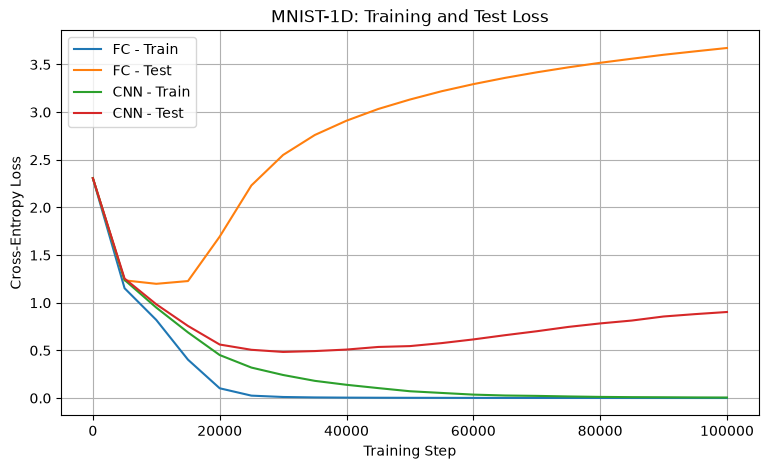

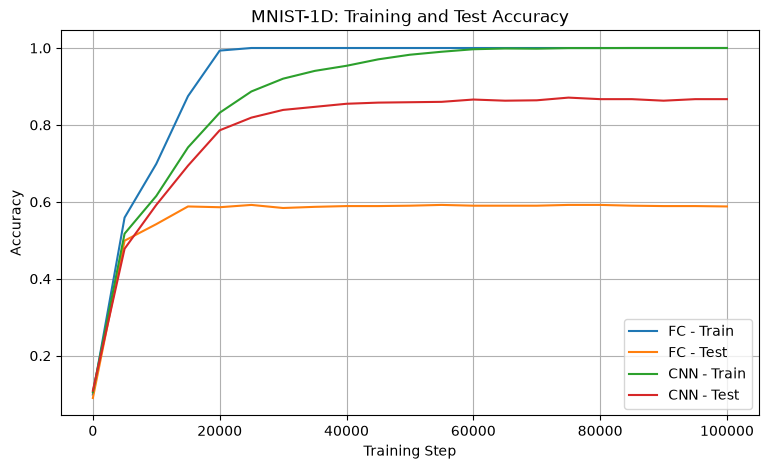

In [119]:
# ============================================================
# 20. Plot Training and Test Loss
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    fc_history["steps"],
    fc_history["train_loss"],
    label="FC - Train"
)

plt.plot(
    fc_history["steps"],
    fc_history["test_loss"],
    label="FC - Test"
)

plt.plot(
    cnn_history["steps"],
    cnn_history["train_loss"],
    label="CNN - Train"
)

plt.plot(
    cnn_history["steps"],
    cnn_history["test_loss"],
    label="CNN - Test"
)

plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss")

plt.title(
    "MNIST-1D: Training and Test Loss"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 21. Plot Training and Test Accuracy
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    fc_history["steps"],
    fc_history["train_acc"],
    label="FC - Train"
)

plt.plot(
    fc_history["steps"],
    fc_history["test_acc"],
    label="FC - Test"
)

plt.plot(
    cnn_history["steps"],
    cnn_history["train_acc"],
    label="CNN - Train"
)

plt.plot(
    cnn_history["steps"],
    cnn_history["test_acc"],
    label="CNN - Test"
)

plt.xlabel("Training Step")
plt.ylabel("Accuracy")

plt.title(
    "MNIST-1D: Training and Test Accuracy"
)

plt.legend()
plt.grid(True)

plt.show()